/pscratch/sd/x/xchong/sam3_finetune/sam3/sam3/model_builder.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Processing single image: /pscratch/sd/x/xchong/sam3_finetune/plants/20211222_125057_petiole4_00993.tiff
Using device: cuda
Patch size: 512x512
Loading ORIGINAL pretrained model...
✓ Original model loaded

Loading FINETUNED model...
✓ Finetuned model loaded

################################################################################
Processing: 20211222_125057_petiole4_00993.tiff
################################################################################
Original image size: 2560 x 2560
Split into 25 patches (5 rows x 5 cols)

  Processing prompt: 'cortex'
    Patch 25/25 (row=4, col=4)
    Stitching object-level patches for 'cortex'...
    Stitching class-level patches for 'cortex'...

  Processing prompt: 'Phloem Fibers'
    Patch 25/25 (row=4, col=4)
    Stitching object-level patches for 'Phloem Fibers'...
    Stitching class-level patches for 'Phloem Fibers'...

  Processing prompt: 'Xylem vessels'
    Patch 25/25 (row=4, col=4)
    Stitching object-level patches for 'Xyl

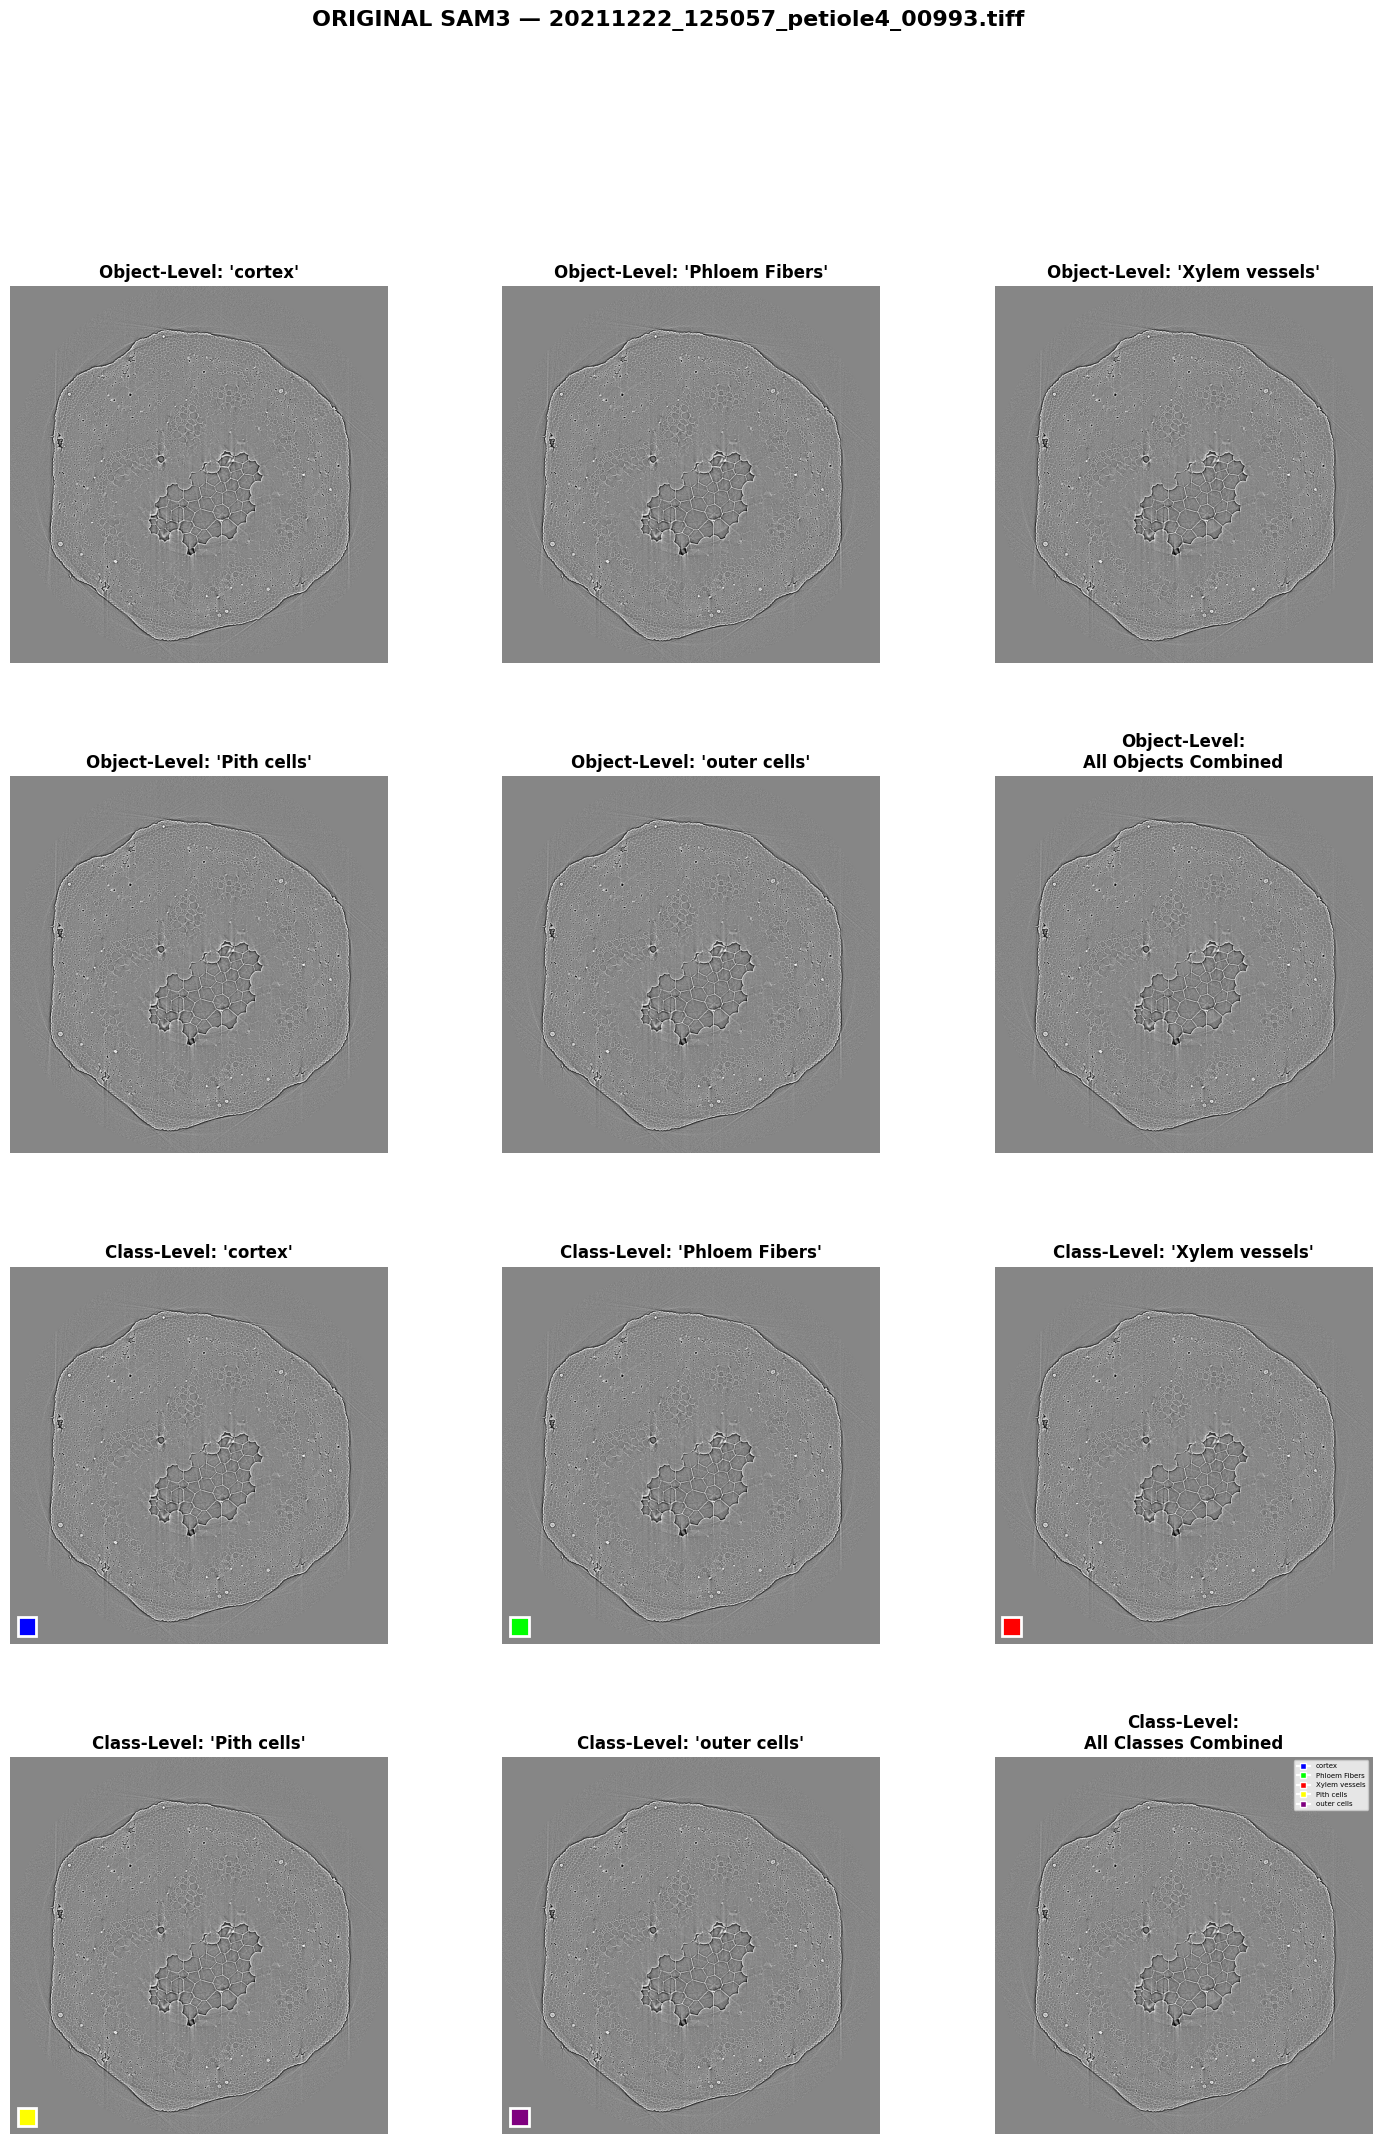


Plotting FINETUNED model results...


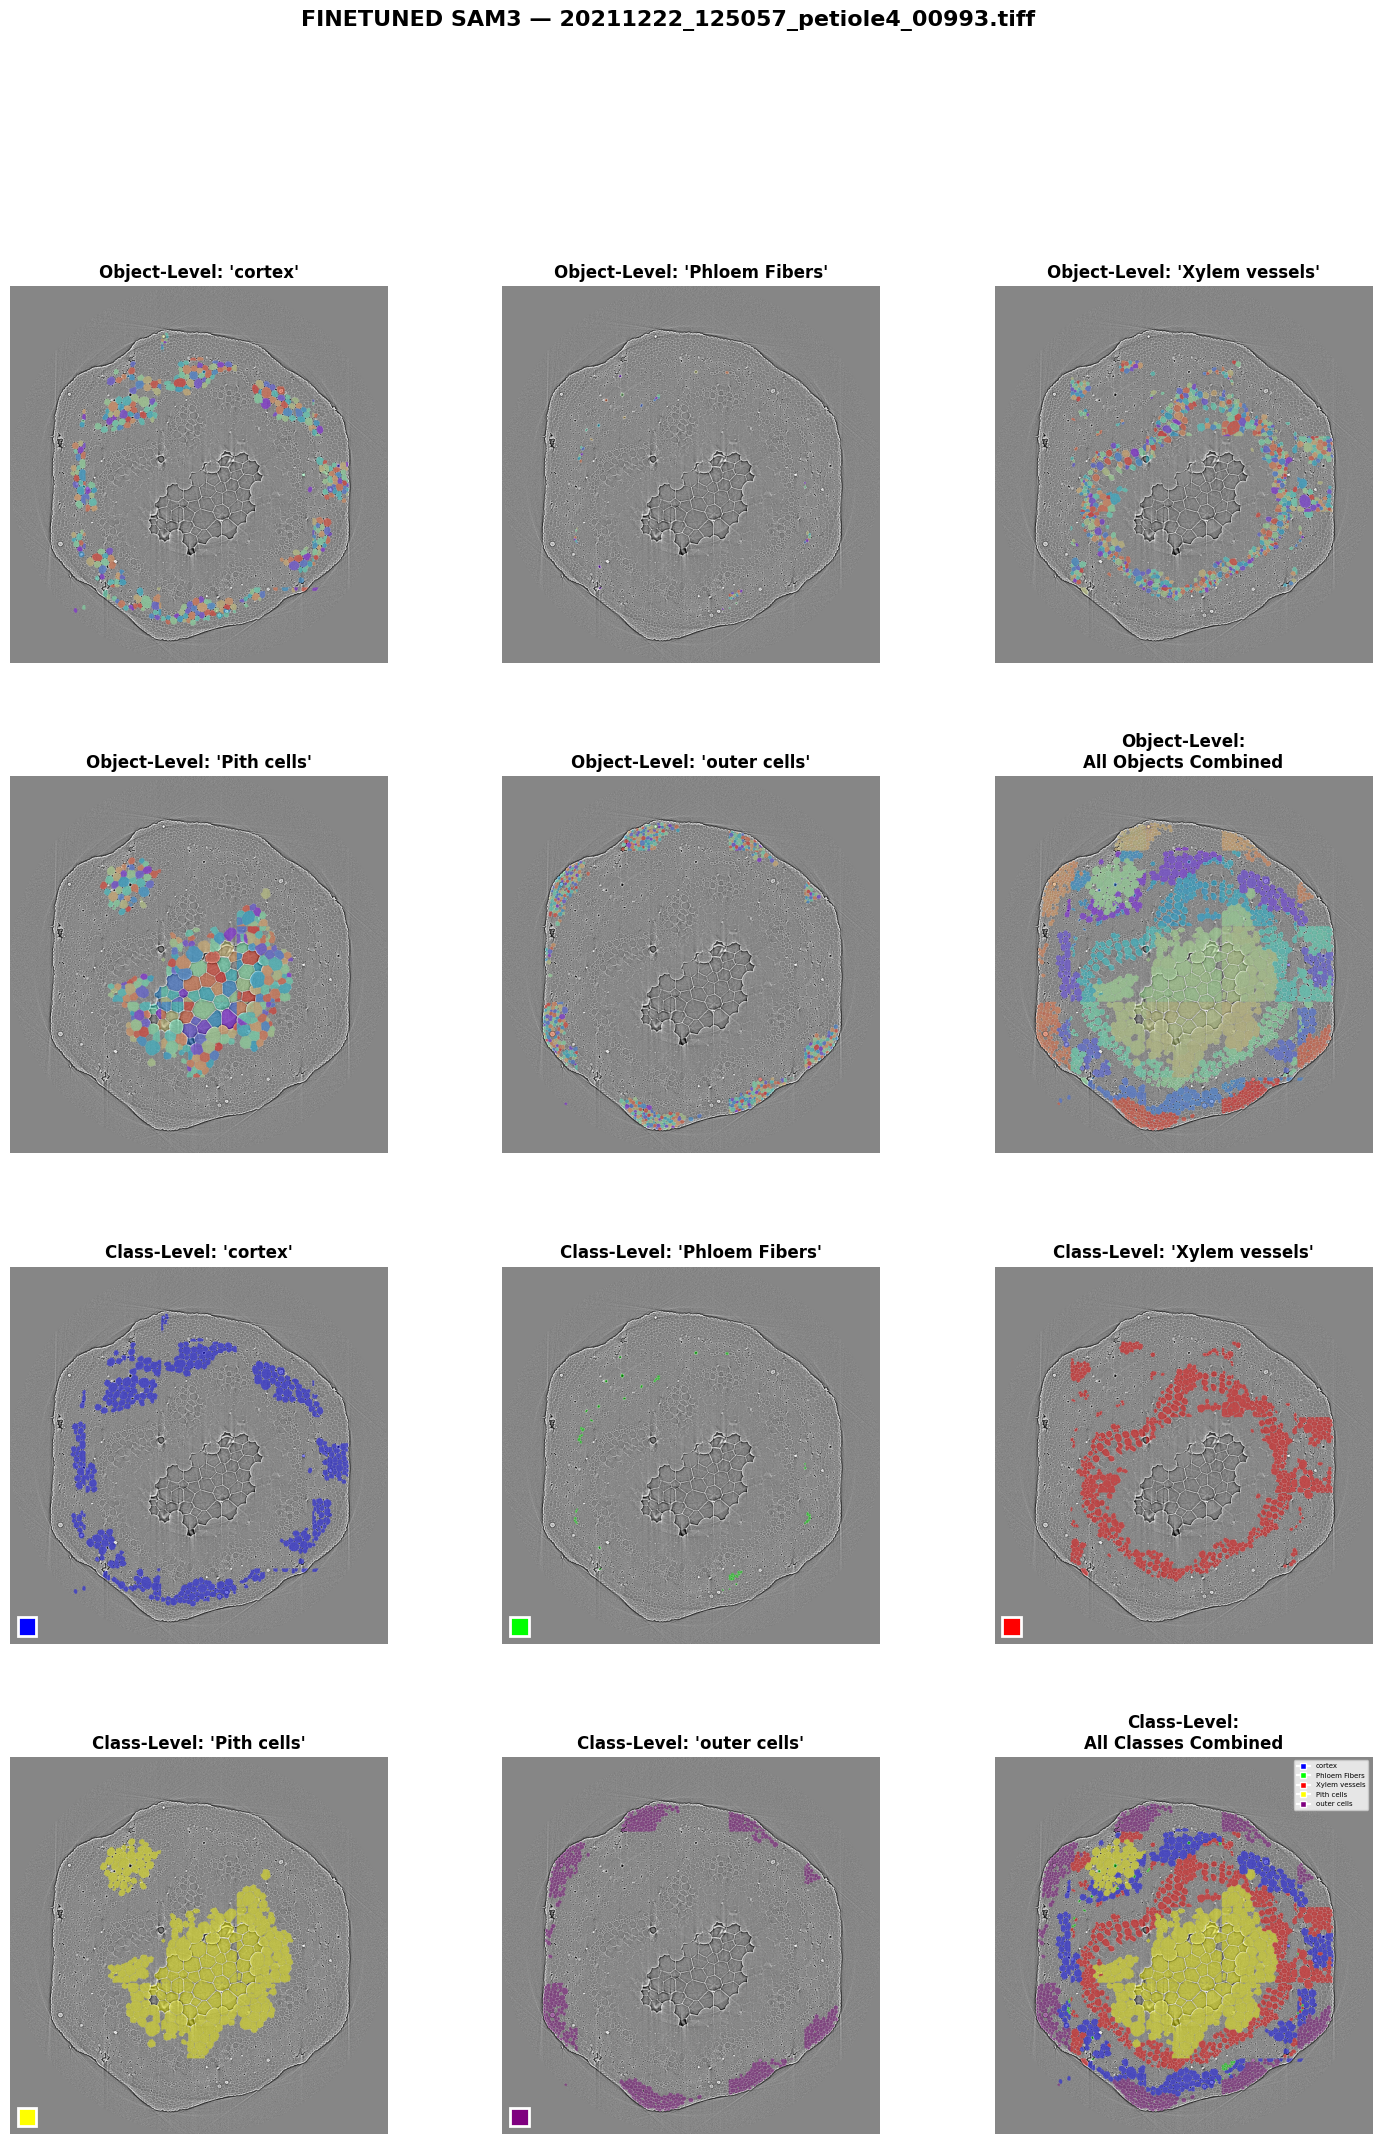


✓ Processing complete!


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

from sam3 import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor


# =============================================================================
# Utils
# =============================================================================
def load_state_dict_flexible(ckpt_path: str) -> dict:
    """Load a checkpoint and return a clean state_dict (no module. prefix)."""
    ckpt = torch.load(ckpt_path, map_location="cpu")
    if isinstance(ckpt, dict):
        if "model" in ckpt:
            state = ckpt["model"]
        elif "state_dict" in ckpt:
            state = ckpt["state_dict"]
        else:
            state = ckpt
    else:
        raise ValueError(f"Unexpected checkpoint type: {type(ckpt)}")

    if any(k.startswith("module.") for k in state.keys()):
        state = {k.replace("module.", ""): v for k, v in state.items()}
    return state


def tif_to_rgb_pil(image_path: str) -> Image.Image:
    img = Image.open(image_path)
    
    # Handle different image modes with proper normalization
    if img.mode not in ['RGB', 'L', 'RGBA']:
        if img.mode in ['I', 'I;16', 'F']:
            # For 16-bit or float images, apply percentile-based contrast stretching
            img_array = np.array(img).astype(np.float32)
            
            p_low = np.percentile(img_array, 0.5)
            p_high = np.percentile(img_array, 99.5)
            
            img_array = np.clip(img_array, p_low, p_high)
            img_array = ((img_array - p_low) / (p_high - p_low) * 255).astype(np.uint8)
            
            img = Image.fromarray(img_array, mode='L')
        else:
            img = img.convert('L')
    
    # Convert to RGB
    if img.mode != "RGB":
        img = img.convert("RGB")
    
    return img


def normalize_for_display(arr: np.ndarray) -> np.ndarray:
    """For display only: normalize to 0..255 uint8 with percentile-based contrast stretching."""
    arr = arr.astype(np.float32)
    
    # Use percentile-based contrast stretching
    p_low = np.percentile(arr, 0.5)
    p_high = np.percentile(arr, 99.5)
    
    # Clip and normalize
    arr = np.clip(arr, p_low, p_high)
    if p_high > p_low:
        arr = ((arr - p_low) / (p_high - p_low) * 255).astype(np.uint8)
    else:
        arr = arr.astype(np.uint8)
    
    return arr


def crop_image_to_patches(image_pil: Image.Image, patch_size: int = 512):
    """
    Crop a PIL image into patches of size patch_size x patch_size.
    Returns list of (patch_pil, row, col, y_start, x_start, patch_h, patch_w) tuples.
    """
    W, H = image_pil.size
    patches = []
    
    n_rows = (H + patch_size - 1) // patch_size
    n_cols = (W + patch_size - 1) // patch_size
    
    for row in range(n_rows):
        for col in range(n_cols):
            y = row * patch_size
            x = col * patch_size
            
            # Calculate actual patch dimensions (handle edges)
            patch_w = min(patch_size, W - x)
            patch_h = min(patch_size, H - y)
            
            # Crop patch
            patch = image_pil.crop((x, y, x + patch_w, y + patch_h))
            
            # If patch is smaller than patch_size, pad it
            if patch_w < patch_size or patch_h < patch_size:
                padded = Image.new('RGB', (patch_size, patch_size), (0, 0, 0))
                padded.paste(patch, (0, 0))
                patch = padded
            
            patches.append((patch, row, col, y, x, patch_h, patch_w))
    
    return patches, H, W, n_rows, n_cols


def render_masks_on_patch(patch_arr: np.ndarray, masks, scores, class_color=None):
    """
    Render masks as colored overlays on a patch image.
    Returns the rendered image as a numpy array.
    
    Args:
        patch_arr: patch image array
        masks: list of masks
        scores: list of scores
        class_color: if provided, use this color for all masks (RGB tuple); otherwise use rainbow colors
    """
    patch_h, patch_w = patch_arr.shape[:2]
    result = patch_arr.copy()
    
    if masks is None or len(masks) == 0:
        return result
    
    # Create overlay
    overlay = np.zeros((patch_h, patch_w, 4), dtype=np.float32)
    
    num_masks = len(masks)
    for i, m in enumerate(masks):
        # Handle mask dimensions
        if m.ndim == 3:
            m = m.squeeze(0)
        
        # Resize if needed
        if m.shape != (patch_h, patch_w):
            m_tensor = torch.from_numpy(m).float()[None, None, ...]
            m_tensor = torch.nn.functional.interpolate(
                m_tensor, size=(patch_h, patch_w), mode="bilinear", align_corners=False
            )
            m = m_tensor.squeeze().numpy()
        
        # Generate color
        if class_color is not None:
            color = class_color
        else:
            color = plt.cm.rainbow(i / max(num_masks, 1))
        
        # Add to overlay
        mask_binary = m > 0.5
        overlay[mask_binary, 0] = color[0]
        overlay[mask_binary, 1] = color[1]
        overlay[mask_binary, 2] = color[2]
        overlay[mask_binary, 3] = 0.45
    
    # Blend overlay with original image
    alpha = overlay[:, :, 3:4]
    result = result * (1 - alpha) + overlay[:, :, :3] * 255 * alpha
    result = result.astype(np.uint8)
    
    return result


def stitch_patch_results(patch_results, orig_h, orig_w, n_rows, n_cols, patch_size=512):
    """
    Stitch rendered patch results back into a full image.
    
    Args:
        patch_results: list of (rendered_patch, row, col, y_start, x_start, patch_h, patch_w)
        orig_h, orig_w: original image dimensions
        n_rows, n_cols: grid dimensions
        patch_size: size of patches
    
    Returns:
        stitched_image: full-size stitched result
    """
    stitched = np.zeros((orig_h, orig_w, 3), dtype=np.uint8)
    
    for rendered_patch, row, col, y_start, x_start, patch_h, patch_w in patch_results:
        # Crop to actual size (remove padding)
        rendered_crop = rendered_patch[:patch_h, :patch_w]
        
        # Place in stitched image
        stitched[y_start:y_start+patch_h, x_start:x_start+patch_w] = rendered_crop
    
    return stitched


def to_numpy(x):
    if x is None:
        return None
    if torch.is_tensor(x):
        return x.detach().float().cpu().numpy()
    return x


def extract_masks_scores(inference_state: dict):
    """Handle common key variants across versions, including empty outputs."""
    masks = inference_state.get("masks", inference_state.get("pred_masks", None))
    scores = inference_state.get("scores", inference_state.get("pred_logits", None))

    masks = to_numpy(masks)
    scores = to_numpy(scores)

    # Normalize scores safely
    if scores is not None:
        scores = np.array(scores)
        if scores.size == 0:
            scores = None
        else:
            if scores.ndim > 1:
                scores = scores.max(axis=-1)
            if scores.size > 0 and (np.nanmax(scores) > 10 or np.nanmin(scores) < -10):
                scores = 1 / (1 + np.exp(-scores))

    # Normalize masks safely
    if masks is not None:
        masks = np.array(masks)
        if masks.size == 0:
            masks = None

    return masks, scores


def create_class_level_visualization(patch_results_dict, orig_h, orig_w, n_rows, n_cols, 
                                    image_arr, class_colors, patch_size=512):
    """
    Create a single class-level visualization with all classes overlaid.
    
    Args:
        patch_results_dict: dict mapping prompt to list of (masks, scores, row, col, y, x, h, w) tuples
        orig_h, orig_w: original image dimensions
        n_rows, n_cols: grid dimensions
        image_arr: original image array
        class_colors: dict mapping prompt to RGB color tuple
        patch_size: size of patches
    
    Returns:
        class_level_image: full-size image with all classes overlaid
    """
    # Start with the original image
    result = normalize_for_display(image_arr)
    
    # Create a combined overlay for all classes
    overlay = np.zeros((orig_h, orig_w, 4), dtype=np.float32)
    
    for prompt, patch_results in patch_results_dict.items():
        color = class_colors[prompt]
        print(f"    Adding class '{prompt}' in color {color}")
        
        for masks, scores, row, col, y_start, x_start, patch_h, patch_w in patch_results:
            if masks is None or len(masks) == 0:
                continue
            
            for m in masks:
                # Handle mask dimensions
                if m.ndim == 3:
                    m = m.squeeze(0)
                
                # Resize to patch size if needed
                if m.shape != (patch_size, patch_size):
                    m_tensor = torch.from_numpy(m).float()[None, None, ...]
                    m_tensor = torch.nn.functional.interpolate(
                        m_tensor, size=(patch_size, patch_size), mode="bilinear", align_corners=False
                    )
                    m = m_tensor.squeeze().numpy()
                
                # Crop to actual patch size
                m_crop = m[:patch_h, :patch_w]
                
                # Place in full overlay
                mask_binary = m_crop > 0.5
                y_end = y_start + patch_h
                x_end = x_start + patch_w
                
                overlay[y_start:y_end, x_start:x_end][mask_binary, 0] = color[0]
                overlay[y_start:y_end, x_start:x_end][mask_binary, 1] = color[1]
                overlay[y_start:y_end, x_start:x_end][mask_binary, 2] = color[2]
                overlay[y_start:y_end, x_start:x_end][mask_binary, 3] = 0.45
    
    # Blend overlay with original image
    alpha = overlay[:, :, 3:4]
    result = result[:, :, None] if result.ndim == 2 else result
    if result.shape[2] == 1:
        result = np.repeat(result, 3, axis=2)
    
    result = result * (1 - alpha) + overlay[:, :, :3] * 255 * alpha
    result = result.astype(np.uint8)
    
    return result


def plot_combined_results(object_results, object_combined, class_results, class_level_img, model_name, class_colors):
    """
    Plot both object-level and class-level visualizations.
    
    Args:
        object_results: dict of prompt -> stitched image (object-level, per prompt)
        object_combined: combined object-level image (all prompts)
        class_results: dict of prompt -> stitched image (class-level, per prompt)
        class_level_img: class-level visualization (all classes combined)
        model_name: name for the figure
        class_colors: dict mapping prompt to RGB color tuple
    """
    num_prompts = len(object_results)
    ncols = 3
    nrows_per_section = (num_prompts + ncols - 1) // ncols
    
    # Total rows: object-level rows + class-level rows
    total_rows = nrows_per_section + nrows_per_section
    
    fig = plt.figure(figsize=(18, 6 * total_rows))
    gs = fig.add_gridspec(total_rows, ncols, hspace=0.3, wspace=0.2)
    
    current_row = 0
    
    # === OBJECT-LEVEL RESULTS (per prompt) ===
    for idx, (prompt, stitched_img) in enumerate(object_results.items()):
        row = idx // ncols
        col = idx % ncols
        ax = fig.add_subplot(gs[current_row + row, col])
        
        ax.imshow(stitched_img)
        ax.set_title(f"Object-Level: '{prompt}'", fontsize=12, fontweight="bold")
        ax.axis("off")
    
    # === OBJECT-LEVEL COMBINED (at last position) ===
    # Place at row 1, col 2 (last column of second row)
    ax_object_combined = fig.add_subplot(gs[current_row + 1, 2])
    ax_object_combined.imshow(object_combined)
    ax_object_combined.set_title(f"Object-Level:\nAll Objects Combined", fontsize=12, fontweight="bold")
    ax_object_combined.axis("off")
    
    current_row += nrows_per_section
    
    # === CLASS-LEVEL RESULTS (per prompt) ===
    for idx, (prompt, stitched_img) in enumerate(class_results.items()):
        row = idx // ncols
        col = idx % ncols
        ax = fig.add_subplot(gs[current_row + row, col])
        
        ax.imshow(stitched_img)
        color = class_colors[prompt]
        ax.set_title(f"Class-Level: '{prompt}'", fontsize=12, fontweight="bold")
        # Add color indicator with smaller font
        ax.add_patch(plt.Rectangle((0.02, 0.02), 0.05, 0.05, 
                                   transform=ax.transAxes,
                                   facecolor=color, edgecolor='white', linewidth=2))
        ax.axis("off")
    
    # === CLASS-LEVEL COMBINED (at last position) ===
    # Place at row (current_row + 1), col 2 (last column of second row)
    ax_class = fig.add_subplot(gs[current_row + 1, 2])
    ax_class.imshow(class_level_img)
    
    # Create legend for class-level with smaller font
    legend_elements = []
    for prompt, color in class_colors.items():
        legend_elements.append(plt.Line2D([0], [0], marker='s', color='w', 
                                         markerfacecolor=color, markersize=5, label=prompt))
    ax_class.legend(handles=legend_elements, loc='upper right', fontsize=5)
    ax_class.set_title(f"Class-Level:\nAll Classes Combined", fontsize=12, fontweight="bold")
    ax_class.axis("off")
    
    fig.suptitle(model_name, fontsize=16, fontweight="bold", y=0.995)
    plt.show()


# =============================================================================
# Main: Multi-prompt inference with patch-based processing
# =============================================================================
if __name__ == "__main__":
    # 1) Setup paths
    sam3_root = "/pscratch/sd/x/xchong/sam3_finetune/sam3"
    finetuned_checkpoint_path = f"{sam3_root}/sam3_logs_plants_with_seg_patches_cleaned/checkpoints/checkpoint.pt"
    original_checkpoint_path = f"{sam3_root}/.cache/huggingface/models--facebook--sam3/snapshots/3c879f39826c281e95690f02c7821c4de09afae7/sam3.pt"
    bpe_path = f"{sam3_root}/assets/bpe_simple_vocab_16e6.txt.gz"

    # Single TIFF file to process
    image_path = "/pscratch/sd/x/xchong/sam3_finetune/plants/20211222_125057_petiole4_00993.tiff"
    
    if not os.path.exists(image_path):
        print(f"Error: Image not found at {image_path}")
        exit(1)
    
    print(f"Processing single image: {image_path}")

    # Define all prompts to test
    TEXT_PROMPTS = [
        "cortex",
        "Phloem Fibers",
        "Xylem vessels",
        "Pith cells",
        "outer cells"
    ]
    
    # Define class colors (RGB tuples, normalized 0-1)
    CLASS_COLORS = {
        "cortex": (0.0, 0.0, 1.0),          # Blue
        "Phloem Fibers": (0.0, 1.0, 0.0),   # Green
        "Xylem vessels": (1.0, 0.0, 0.0),   # Red
        "Pith cells": (1.0, 1.0, 0.0),      # Yellow
        "outer cells": (0.5, 0.0, 0.5)      # Purple
    }
    
    PATCH_SIZE = 512
    CONF_THRESH = 0.5
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")
    print(f"Patch size: {PATCH_SIZE}x{PATCH_SIZE}")

    # 2) Load ORIGINAL pretrained model
    print("=" * 60)
    print("Loading ORIGINAL pretrained model...")
    print("=" * 60)

    original_state = load_state_dict_flexible(original_checkpoint_path)

    model_original = build_sam3_image_model(
        bpe_path=bpe_path,
        device=device,
        eval_mode=True,
        enable_segmentation=True
    )
    _ = model_original.load_state_dict(original_state, strict=False)
    model_original.eval().to(device)
    print("✓ Original model loaded")

    # 3) Load FINETUNED model
    print("\n" + "=" * 60)
    print("Loading FINETUNED model...")
    print("=" * 60)

    model_finetuned = build_sam3_image_model(
        bpe_path=bpe_path,
        device=device,
        eval_mode=True,
        enable_segmentation=True
    )
    _ = model_finetuned.load_state_dict(original_state, strict=False)

    finetuned_state = load_state_dict_flexible(finetuned_checkpoint_path)
    missing_keys, unexpected_keys = model_finetuned.load_state_dict(finetuned_state, strict=False)
    if missing_keys:
        print(f"⚠ Missing keys: {len(missing_keys)}")
    if unexpected_keys:
        print(f"⚠ Unexpected keys: {len(unexpected_keys)}")

    model_finetuned.eval().to(device)
    print("✓ Finetuned model loaded")

    # 4) Create processors
    processor_original = Sam3Processor(model_original, confidence_threshold=CONF_THRESH)
    processor_finetuned = Sam3Processor(model_finetuned, confidence_threshold=CONF_THRESH)

    # 5) Process the single image
    print("\n" + "#" * 80)
    print(f"Processing: {os.path.basename(image_path)}")
    print("#" * 80)

    # Load full image
    image_pil = tif_to_rgb_pil(image_path)
    W, H = image_pil.size
    print(f"Original image size: {W} x {H}")
    
    # Crop into patches
    patches, orig_h, orig_w, n_rows, n_cols = crop_image_to_patches(image_pil, PATCH_SIZE)
    print(f"Split into {len(patches)} patches ({n_rows} rows x {n_cols} cols)")

    # Store results for all prompts
    object_results_original = {}
    object_results_finetuned = {}
    
    class_results_original = {}
    class_results_finetuned = {}
    
    # Store raw patch results for class-level visualization
    raw_patch_results_original = {}
    raw_patch_results_finetuned = {}

    # Process each prompt
    for prompt in TEXT_PROMPTS:
        print(f"\n  Processing prompt: '{prompt}'")
        
        # Object-level rendering (rainbow colors)
        object_patches_original = []
        object_patches_finetuned = []
        
        # Class-level rendering (single color per class)
        class_patches_original = []
        class_patches_finetuned = []
        
        # Raw results for class-level visualization
        raw_results_original = []
        raw_results_finetuned = []
        
        # Get class color for this prompt
        class_color = CLASS_COLORS[prompt]
        
        # Process each patch
        for patch_idx, (patch_pil, row, col, y_start, x_start, patch_h, patch_w) in enumerate(patches):
            print(f"    Patch {patch_idx+1}/{len(patches)} (row={row}, col={col})", end="\r")
            
            patch_arr = np.array(patch_pil)
            
            # ----- ORIGINAL -----
            state_o = processor_original.set_image(patch_pil)
            processor_original.reset_all_prompts(state_o)
            state_o = processor_original.set_text_prompt(state=state_o, prompt=prompt)
            masks_o, scores_o = extract_masks_scores(state_o)
            
            # Store raw results for class-level viz
            raw_results_original.append((masks_o, scores_o, row, col, y_start, x_start, patch_h, patch_w))
            
            # Render masks on patch - object-level (rainbow colors)
            rendered_object_o = render_masks_on_patch(patch_arr, masks_o, scores_o, class_color=None)
            object_patches_original.append((rendered_object_o, row, col, y_start, x_start, patch_h, patch_w))
            
            # ----- FINETUNED -----
            state_f = processor_finetuned.set_image(patch_pil)
            processor_finetuned.reset_all_prompts(state_f)
            state_f = processor_finetuned.set_text_prompt(state=state_f, prompt=prompt)
            masks_f, scores_f = extract_masks_scores(state_f)
            
            # Store raw results for class-level viz
            raw_results_finetuned.append((masks_f, scores_f, row, col, y_start, x_start, patch_h, patch_w))
            
            # Render masks on patch - object-level (rainbow colors)
            rendered_object_f = render_masks_on_patch(patch_arr, masks_f, scores_f, class_color=None)
            object_patches_finetuned.append((rendered_object_f, row, col, y_start, x_start, patch_h, patch_w))
        
        print()  # New line after progress
        
        # Store raw results
        raw_patch_results_original[prompt] = raw_results_original
        raw_patch_results_finetuned[prompt] = raw_results_finetuned
        
        # Stitch patches back together for object-level
        print(f"    Stitching object-level patches for '{prompt}'...")
        stitched_object_o = stitch_patch_results(object_patches_original, orig_h, orig_w, n_rows, n_cols, PATCH_SIZE)
        stitched_object_f = stitch_patch_results(object_patches_finetuned, orig_h, orig_w, n_rows, n_cols, PATCH_SIZE)
        
        object_results_original[prompt] = stitched_object_o
        object_results_finetuned[prompt] = stitched_object_f
        
        # Stitch patches back together for class-level (per prompt)
        print(f"    Stitching class-level patches for '{prompt}'...")
        class_patches_original = []
        class_patches_finetuned = []
        
        for patch_idx, (patch_pil, row, col, y_start, x_start, patch_h, patch_w) in enumerate(patches):
            patch_arr = np.array(patch_pil)
            
            # Get masks for this patch
            masks_o, scores_o, _, _, _, _, _, _ = raw_results_original[patch_idx]
            masks_f, scores_f, _, _, _, _, _, _ = raw_results_finetuned[patch_idx]
            
            # Render with class color
            rendered_class_o = render_masks_on_patch(patch_arr, masks_o, scores_o, class_color=class_color)
            rendered_class_f = render_masks_on_patch(patch_arr, masks_f, scores_f, class_color=class_color)
            
            class_patches_original.append((rendered_class_o, row, col, y_start, x_start, patch_h, patch_w))
            class_patches_finetuned.append((rendered_class_f, row, col, y_start, x_start, patch_h, patch_w))
        
        stitched_class_o = stitch_patch_results(class_patches_original, orig_h, orig_w, n_rows, n_cols, PATCH_SIZE)
        stitched_class_f = stitch_patch_results(class_patches_finetuned, orig_h, orig_w, n_rows, n_cols, PATCH_SIZE)
        
        class_results_original[prompt] = stitched_class_o
        class_results_finetuned[prompt] = stitched_class_f

    # Create class-level visualizations (all classes combined)
    print("\n  Creating class-level visualization (all classes combined)...")
    image_arr = np.array(image_pil)
    class_level_combined_original = create_class_level_visualization(
        raw_patch_results_original, orig_h, orig_w, n_rows, n_cols,
        image_arr, CLASS_COLORS, PATCH_SIZE
    )
    class_level_combined_finetuned = create_class_level_visualization(
        raw_patch_results_finetuned, orig_h, orig_w, n_rows, n_cols,
        image_arr, CLASS_COLORS, PATCH_SIZE
    )
    
    # Create object-level combined visualization (all prompts with rainbow colors)
    print("\n  Creating object-level visualization (all objects combined)...")
    object_combined_original = np.array(image_pil).copy()
    object_combined_finetuned = np.array(image_pil).copy()
    
    # Combine all object-level masks
    all_masks_original = []
    all_masks_finetuned = []
    
    for prompt, raw_results in raw_patch_results_original.items():
        for masks, scores, row, col, y_start, x_start, patch_h, patch_w in raw_results:
            if masks is not None and len(masks) > 0:
                for m in masks:
                    all_masks_original.append((m, y_start, x_start, patch_h, patch_w))
    
    for prompt, raw_results in raw_patch_results_finetuned.items():
        for masks, scores, row, col, y_start, x_start, patch_h, patch_w in raw_results:
            if masks is not None and len(masks) > 0:
                for m in masks:
                    all_masks_finetuned.append((m, y_start, x_start, patch_h, patch_w))
    
    # Render all masks with rainbow colors
    def render_all_objects(image_arr, all_masks_list, orig_h, orig_w):
        result = normalize_for_display(image_arr)
        if result.ndim == 2:
            result = np.stack([result] * 3, axis=-1)
        
        overlay = np.zeros((orig_h, orig_w, 4), dtype=np.float32)
        num_total_masks = len(all_masks_list)
        
        for idx, (m, y_start, x_start, patch_h, patch_w) in enumerate(all_masks_list):
            # Generate rainbow color for this mask
            color = plt.cm.rainbow(idx / max(num_total_masks, 1))
            
            # Handle mask dimensions
            if m.ndim == 3:
                m = m.squeeze(0)
            
            # Resize to patch size if needed
            if m.shape != (PATCH_SIZE, PATCH_SIZE):
                m_tensor = torch.from_numpy(m).float()[None, None, ...]
                m_tensor = torch.nn.functional.interpolate(
                    m_tensor, size=(PATCH_SIZE, PATCH_SIZE), mode="bilinear", align_corners=False
                )
                m = m_tensor.squeeze().numpy()
            
            # Crop to actual patch size
            m_crop = m[:patch_h, :patch_w]
            
            # Place in full overlay
            mask_binary = m_crop > 0.5
            y_end = y_start + patch_h
            x_end = x_start + patch_w
            
            overlay[y_start:y_end, x_start:x_end][mask_binary, 0] = color[0]
            overlay[y_start:y_end, x_start:x_end][mask_binary, 1] = color[1]
            overlay[y_start:y_end, x_start:x_end][mask_binary, 2] = color[2]
            overlay[y_start:y_end, x_start:x_end][mask_binary, 3] = 0.45
        
        # Blend overlay with original image
        alpha = overlay[:, :, 3:4]
        result = result * (1 - alpha) + overlay[:, :, :3] * 255 * alpha
        result = result.astype(np.uint8)
        
        return result
    
    object_combined_original = render_all_objects(image_arr, all_masks_original, orig_h, orig_w)
    object_combined_finetuned = render_all_objects(image_arr, all_masks_finetuned, orig_h, orig_w)

    # Plot combined results
    print("\n" + "=" * 60)
    print("Plotting ORIGINAL model results...")
    print("=" * 60)
    plot_combined_results(
        object_results_original,
        object_combined_original,
        class_results_original,
        class_level_combined_original,
        f"ORIGINAL SAM3 — {os.path.basename(image_path)}",
        CLASS_COLORS
    )
    
    print("\n" + "=" * 60)
    print("Plotting FINETUNED model results...")
    print("=" * 60)
    plot_combined_results(
        object_results_finetuned,
        object_combined_finetuned,
        class_results_finetuned,
        class_level_combined_finetuned,
        f"FINETUNED SAM3 — {os.path.basename(image_path)}",
        CLASS_COLORS
    )
    
    print("\n" + "=" * 80)
    print("✓ Processing complete!")
    print("=" * 80)

Processing single image: /pscratch/sd/x/xchong/sam3_finetune/plants/20211222_113313_petiole3_00005.tiff
Using device: cuda
Patch size: 512x512
Loading ORIGINAL pretrained model...
Mapping parameter names (detector.* -> backbone.*)...
✓ Original model loaded

Loading FINETUNED model...
✓ Finetuned model loaded

################################################################################
Processing: 20211222_113313_petiole3_00005.tiff
################################################################################
Original image size: 2560 x 2560
Split into 25 patches (5 rows x 5 cols)

  Processing prompt: 'cortex'
    Patch 25/25 (row=4, col=4)
    Stitching object-level patches for 'cortex'...
    Stitching class-level patches for 'cortex'...

  Processing prompt: 'Phloem Fibers'
    Patch 25/25 (row=4, col=4)
    Stitching object-level patches for 'Phloem Fibers'...
    Stitching class-level patches for 'Phloem Fibers'...

  Processing prompt: 'Xylem vessels'
    Patch 25/25 (row

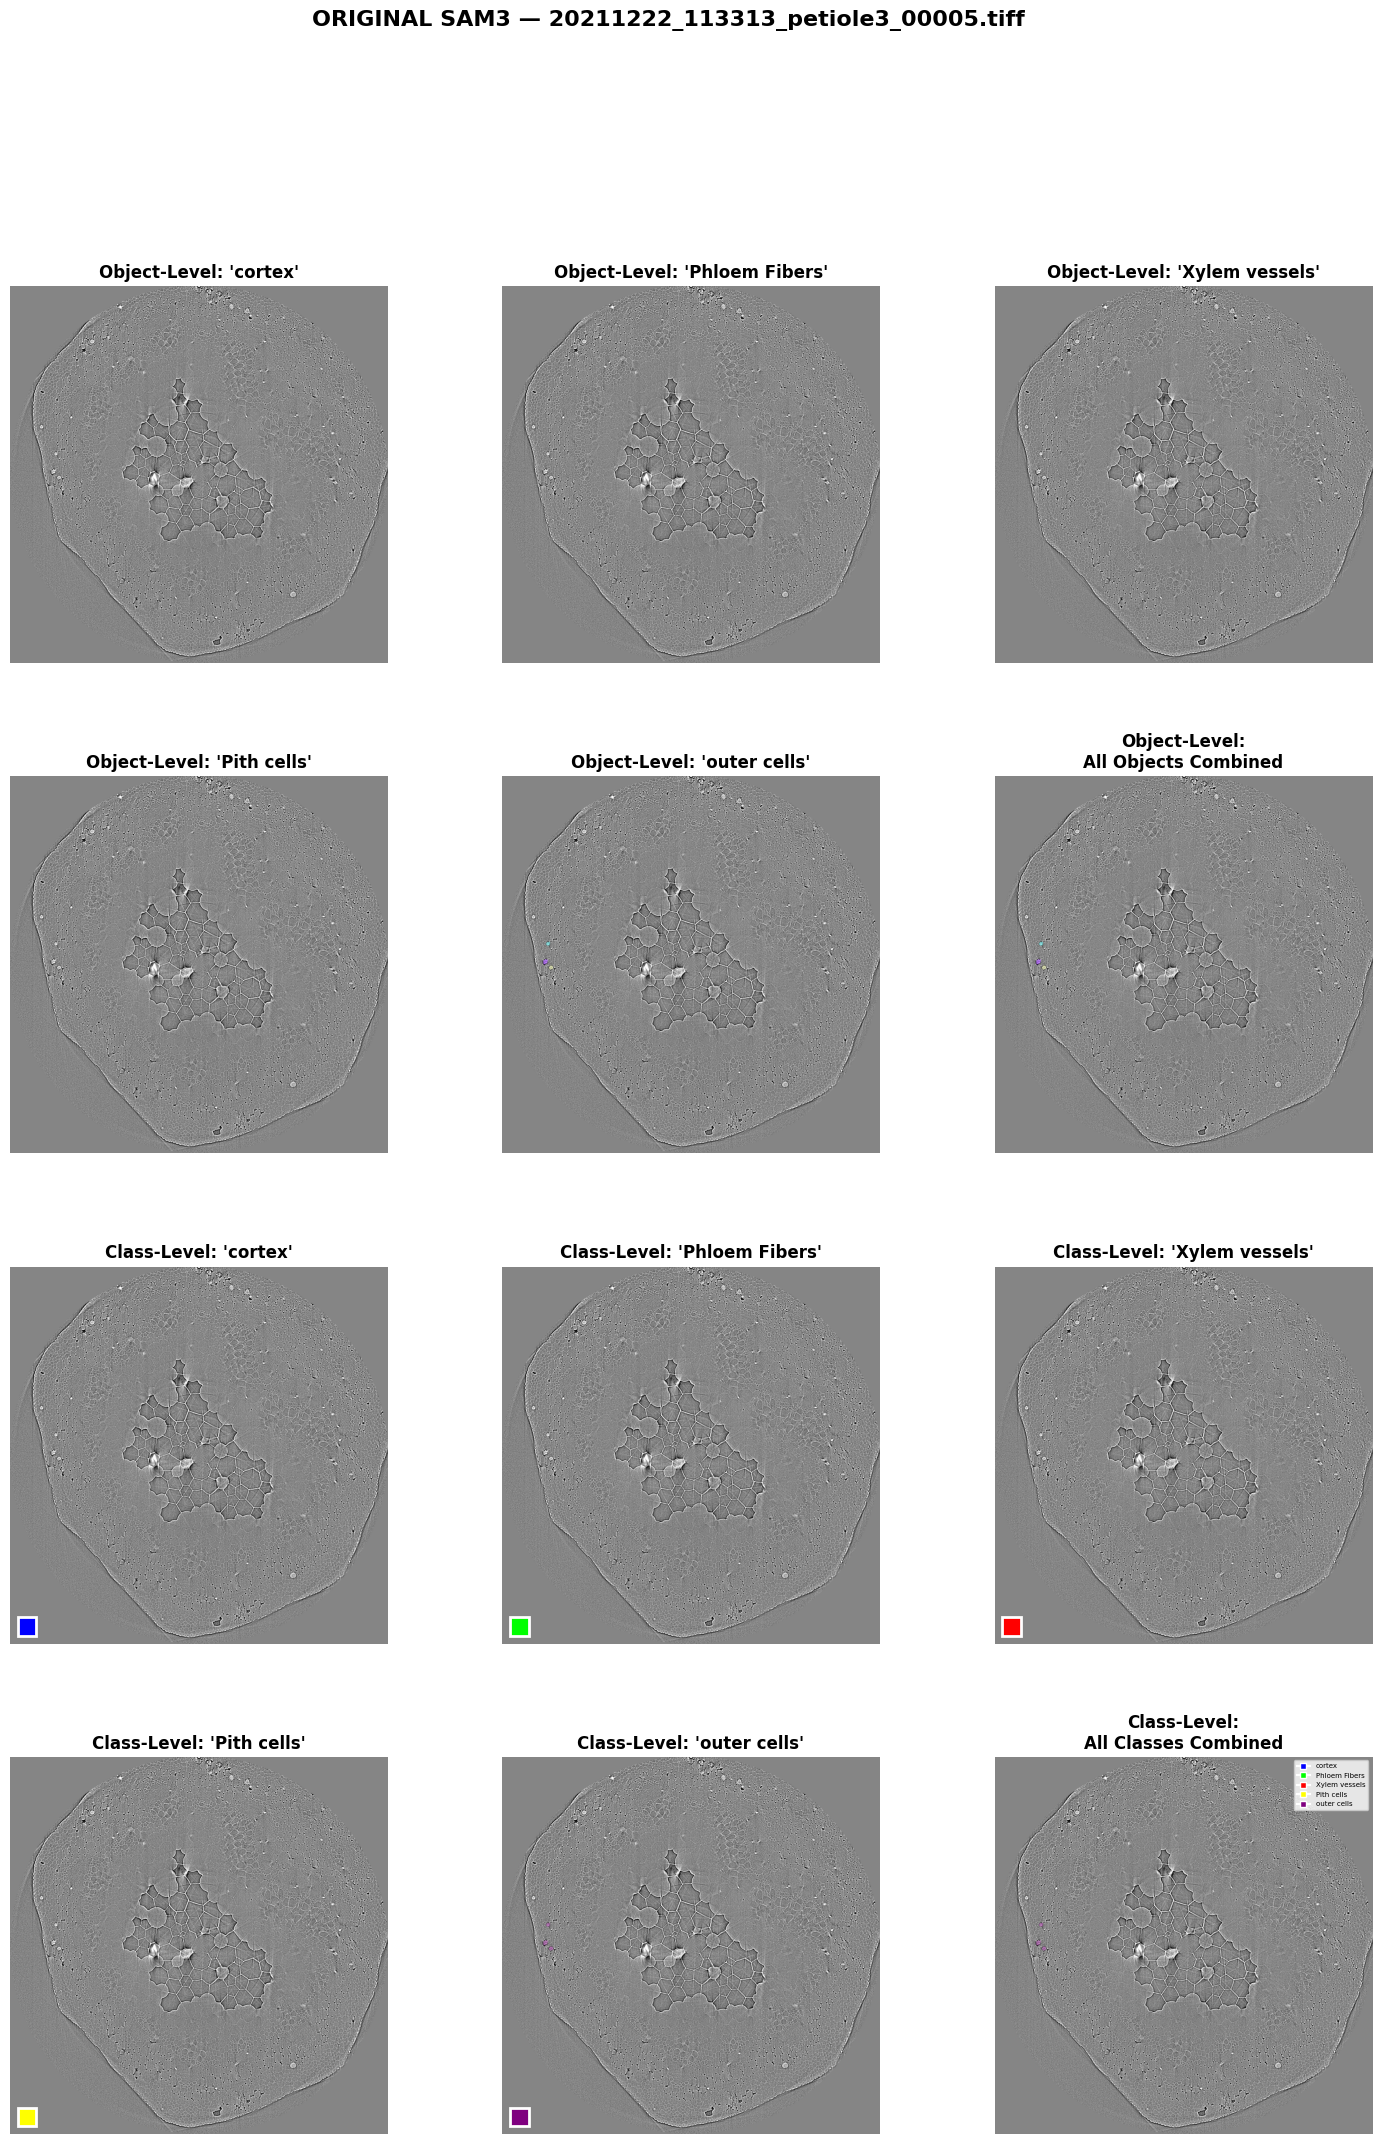


Plotting FINETUNED model results...


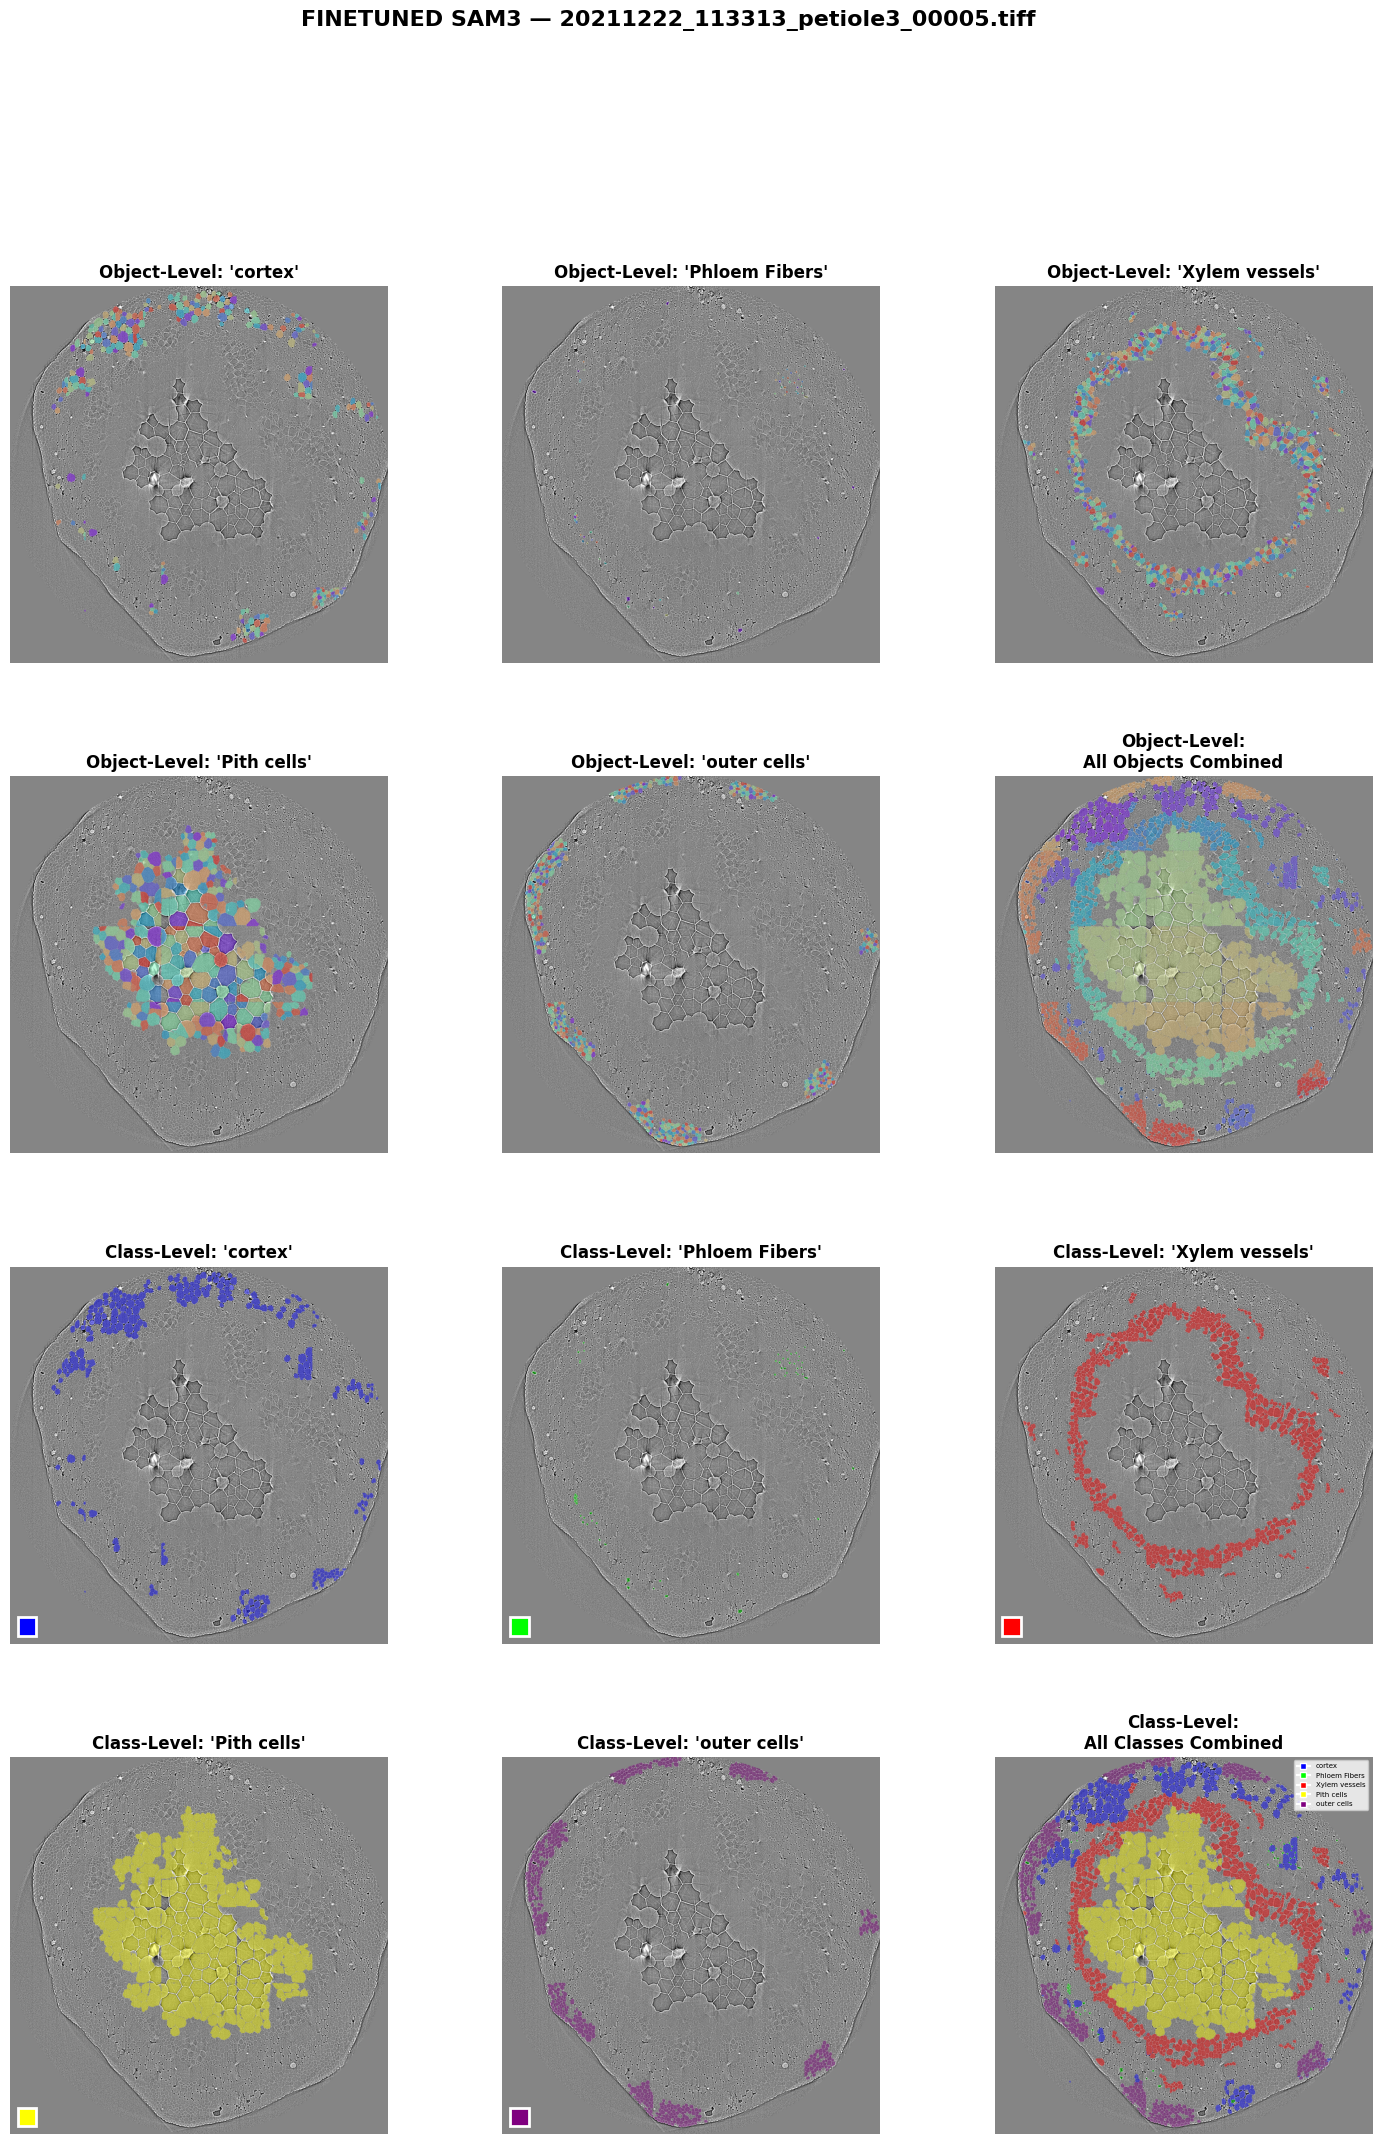


✓ Processing complete!


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

from sam3 import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor


# =============================================================================
# Utils
# =============================================================================
def load_state_dict_flexible(ckpt_path: str) -> dict:
    """Load a checkpoint and return a clean state_dict (no module. prefix)."""
    ckpt = torch.load(ckpt_path, map_location="cpu")
    if isinstance(ckpt, dict):
        if "model" in ckpt:
            state = ckpt["model"]
        elif "state_dict" in ckpt:
            state = ckpt["state_dict"]
        else:
            state = ckpt
    else:
        raise ValueError(f"Unexpected checkpoint type: {type(ckpt)}")

    if any(k.startswith("module.") for k in state.keys()):
        state = {k.replace("module.", ""): v for k, v in state.items()}
    return state


def tif_to_rgb_pil(image_path: str) -> Image.Image:
    img = Image.open(image_path)
    
    # Handle different image modes with proper normalization
    if img.mode not in ['RGB', 'L', 'RGBA']:
        if img.mode in ['I', 'I;16', 'F']:
            # For 16-bit or float images, apply percentile-based contrast stretching
            img_array = np.array(img).astype(np.float32)
            
            p_low = np.percentile(img_array, 0.5)
            p_high = np.percentile(img_array, 99.5)
            
            img_array = np.clip(img_array, p_low, p_high)
            img_array = ((img_array - p_low) / (p_high - p_low) * 255).astype(np.uint8)
            
            img = Image.fromarray(img_array, mode='L')
        else:
            img = img.convert('L')
    
    # Convert to RGB
    if img.mode != "RGB":
        img = img.convert("RGB")
    
    return img


def normalize_for_display(arr: np.ndarray) -> np.ndarray:
    """For display only: normalize to 0..255 uint8 with percentile-based contrast stretching."""
    arr = arr.astype(np.float32)
    
    # Use percentile-based contrast stretching
    p_low = np.percentile(arr, 0.5)
    p_high = np.percentile(arr, 99.5)
    
    # Clip and normalize
    arr = np.clip(arr, p_low, p_high)
    if p_high > p_low:
        arr = ((arr - p_low) / (p_high - p_low) * 255).astype(np.uint8)
    else:
        arr = arr.astype(np.uint8)
    
    return arr


def crop_image_to_patches(image_pil: Image.Image, patch_size: int = 512):
    """
    Crop a PIL image into patches of size patch_size x patch_size.
    Returns list of (patch_pil, row, col, y_start, x_start, patch_h, patch_w) tuples.
    """
    W, H = image_pil.size
    patches = []
    
    n_rows = (H + patch_size - 1) // patch_size
    n_cols = (W + patch_size - 1) // patch_size
    
    for row in range(n_rows):
        for col in range(n_cols):
            y = row * patch_size
            x = col * patch_size
            
            # Calculate actual patch dimensions (handle edges)
            patch_w = min(patch_size, W - x)
            patch_h = min(patch_size, H - y)
            
            # Crop patch
            patch = image_pil.crop((x, y, x + patch_w, y + patch_h))
            
            # If patch is smaller than patch_size, pad it
            if patch_w < patch_size or patch_h < patch_size:
                padded = Image.new('RGB', (patch_size, patch_size), (0, 0, 0))
                padded.paste(patch, (0, 0))
                patch = padded
            
            patches.append((patch, row, col, y, x, patch_h, patch_w))
    
    return patches, H, W, n_rows, n_cols


def render_masks_on_patch(patch_arr: np.ndarray, masks, scores, class_color=None):
    """
    Render masks as colored overlays on a patch image.
    Returns the rendered image as a numpy array.
    
    Args:
        patch_arr: patch image array
        masks: list of masks
        scores: list of scores
        class_color: if provided, use this color for all masks (RGB tuple); otherwise use rainbow colors
    """
    patch_h, patch_w = patch_arr.shape[:2]
    result = patch_arr.copy()
    
    if masks is None or len(masks) == 0:
        return result
    
    # Create overlay
    overlay = np.zeros((patch_h, patch_w, 4), dtype=np.float32)
    
    num_masks = len(masks)
    for i, m in enumerate(masks):
        # Handle mask dimensions
        if m.ndim == 3:
            m = m.squeeze(0)
        
        # Resize if needed
        if m.shape != (patch_h, patch_w):
            m_tensor = torch.from_numpy(m).float()[None, None, ...]
            m_tensor = torch.nn.functional.interpolate(
                m_tensor, size=(patch_h, patch_w), mode="bilinear", align_corners=False
            )
            m = m_tensor.squeeze().numpy()
        
        # Generate color
        if class_color is not None:
            color = class_color
        else:
            color = plt.cm.rainbow(i / max(num_masks, 1))
        
        # Add to overlay
        mask_binary = m > 0.5
        overlay[mask_binary, 0] = color[0]
        overlay[mask_binary, 1] = color[1]
        overlay[mask_binary, 2] = color[2]
        overlay[mask_binary, 3] = 0.45
    
    # Blend overlay with original image
    alpha = overlay[:, :, 3:4]
    result = result * (1 - alpha) + overlay[:, :, :3] * 255 * alpha
    result = result.astype(np.uint8)
    
    return result


def stitch_patch_results(patch_results, orig_h, orig_w, n_rows, n_cols, patch_size=512):
    """
    Stitch rendered patch results back into a full image.
    
    Args:
        patch_results: list of (rendered_patch, row, col, y_start, x_start, patch_h, patch_w)
        orig_h, orig_w: original image dimensions
        n_rows, n_cols: grid dimensions
        patch_size: size of patches
    
    Returns:
        stitched_image: full-size stitched result
    """
    stitched = np.zeros((orig_h, orig_w, 3), dtype=np.uint8)
    
    for rendered_patch, row, col, y_start, x_start, patch_h, patch_w in patch_results:
        # Crop to actual size (remove padding)
        rendered_crop = rendered_patch[:patch_h, :patch_w]
        
        # Place in stitched image
        stitched[y_start:y_start+patch_h, x_start:x_start+patch_w] = rendered_crop
    
    return stitched


def to_numpy(x):
    if x is None:
        return None
    if torch.is_tensor(x):
        return x.detach().float().cpu().numpy()
    return x


def extract_masks_scores(inference_state: dict):
    """Handle common key variants across versions, including empty outputs."""
    masks = inference_state.get("masks", inference_state.get("pred_masks", None))
    scores = inference_state.get("scores", inference_state.get("pred_logits", None))

    masks = to_numpy(masks)
    scores = to_numpy(scores)

    # Normalize scores safely
    if scores is not None:
        scores = np.array(scores)
        if scores.size == 0:
            scores = None
        else:
            if scores.ndim > 1:
                scores = scores.max(axis=-1)
            if scores.size > 0 and (np.nanmax(scores) > 10 or np.nanmin(scores) < -10):
                scores = 1 / (1 + np.exp(-scores))

    # Normalize masks safely
    if masks is not None:
        masks = np.array(masks)
        if masks.size == 0:
            masks = None

    return masks, scores


def create_class_level_visualization(patch_results_dict, orig_h, orig_w, n_rows, n_cols, 
                                    image_arr, class_colors, patch_size=512):
    """
    Create a single class-level visualization with all classes overlaid.
    
    Args:
        patch_results_dict: dict mapping prompt to list of (masks, scores, row, col, y, x, h, w) tuples
        orig_h, orig_w: original image dimensions
        n_rows, n_cols: grid dimensions
        image_arr: original image array
        class_colors: dict mapping prompt to RGB color tuple
        patch_size: size of patches
    
    Returns:
        class_level_image: full-size image with all classes overlaid
    """
    # Start with the original image
    result = normalize_for_display(image_arr)
    
    # Create a combined overlay for all classes
    overlay = np.zeros((orig_h, orig_w, 4), dtype=np.float32)
    
    for prompt, patch_results in patch_results_dict.items():
        color = class_colors[prompt]
        print(f"    Adding class '{prompt}' in color {color}")
        
        for masks, scores, row, col, y_start, x_start, patch_h, patch_w in patch_results:
            if masks is None or len(masks) == 0:
                continue
            
            for m in masks:
                # Handle mask dimensions
                if m.ndim == 3:
                    m = m.squeeze(0)
                
                # Resize to patch size if needed
                if m.shape != (patch_size, patch_size):
                    m_tensor = torch.from_numpy(m).float()[None, None, ...]
                    m_tensor = torch.nn.functional.interpolate(
                        m_tensor, size=(patch_size, patch_size), mode="bilinear", align_corners=False
                    )
                    m = m_tensor.squeeze().numpy()
                
                # Crop to actual patch size
                m_crop = m[:patch_h, :patch_w]
                
                # Place in full overlay
                mask_binary = m_crop > 0.5
                y_end = y_start + patch_h
                x_end = x_start + patch_w
                
                overlay[y_start:y_end, x_start:x_end][mask_binary, 0] = color[0]
                overlay[y_start:y_end, x_start:x_end][mask_binary, 1] = color[1]
                overlay[y_start:y_end, x_start:x_end][mask_binary, 2] = color[2]
                overlay[y_start:y_end, x_start:x_end][mask_binary, 3] = 0.45
    
    # Blend overlay with original image
    alpha = overlay[:, :, 3:4]
    result = result[:, :, None] if result.ndim == 2 else result
    if result.shape[2] == 1:
        result = np.repeat(result, 3, axis=2)
    
    result = result * (1 - alpha) + overlay[:, :, :3] * 255 * alpha
    result = result.astype(np.uint8)
    
    return result


def plot_combined_results(object_results, object_combined, class_results, class_level_img, model_name, class_colors):
    """
    Plot both object-level and class-level visualizations.
    
    Args:
        object_results: dict of prompt -> stitched image (object-level, per prompt)
        object_combined: combined object-level image (all prompts)
        class_results: dict of prompt -> stitched image (class-level, per prompt)
        class_level_img: class-level visualization (all classes combined)
        model_name: name for the figure
        class_colors: dict mapping prompt to RGB color tuple
    """
    num_prompts = len(object_results)
    ncols = 3
    nrows_per_section = (num_prompts + ncols - 1) // ncols
    
    # Total rows: object-level rows + class-level rows
    total_rows = nrows_per_section + nrows_per_section
    
    fig = plt.figure(figsize=(18, 6 * total_rows))
    gs = fig.add_gridspec(total_rows, ncols, hspace=0.3, wspace=0.2)
    
    current_row = 0
    
    # === OBJECT-LEVEL RESULTS (per prompt) ===
    for idx, (prompt, stitched_img) in enumerate(object_results.items()):
        row = idx // ncols
        col = idx % ncols
        ax = fig.add_subplot(gs[current_row + row, col])
        
        ax.imshow(stitched_img)
        ax.set_title(f"Object-Level: '{prompt}'", fontsize=12, fontweight="bold")
        ax.axis("off")
    
    # === OBJECT-LEVEL COMBINED (at last position) ===
    # Place at row 1, col 2 (last column of second row)
    ax_object_combined = fig.add_subplot(gs[current_row + 1, 2])
    ax_object_combined.imshow(object_combined)
    ax_object_combined.set_title(f"Object-Level:\nAll Objects Combined", fontsize=12, fontweight="bold")
    ax_object_combined.axis("off")
    
    current_row += nrows_per_section
    
    # === CLASS-LEVEL RESULTS (per prompt) ===
    for idx, (prompt, stitched_img) in enumerate(class_results.items()):
        row = idx // ncols
        col = idx % ncols
        ax = fig.add_subplot(gs[current_row + row, col])
        
        ax.imshow(stitched_img)
        color = class_colors[prompt]
        ax.set_title(f"Class-Level: '{prompt}'", fontsize=12, fontweight="bold")
        # Add color indicator with smaller font
        ax.add_patch(plt.Rectangle((0.02, 0.02), 0.05, 0.05, 
                                   transform=ax.transAxes,
                                   facecolor=color, edgecolor='white', linewidth=2))
        ax.axis("off")
    
    # === CLASS-LEVEL COMBINED (at last position) ===
    # Place at row (current_row + 1), col 2 (last column of second row)
    ax_class = fig.add_subplot(gs[current_row + 1, 2])
    ax_class.imshow(class_level_img)
    
    # Create legend for class-level with smaller font
    legend_elements = []
    for prompt, color in class_colors.items():
        legend_elements.append(plt.Line2D([0], [0], marker='s', color='w', 
                                         markerfacecolor=color, markersize=5, label=prompt))
    ax_class.legend(handles=legend_elements, loc='upper right', fontsize=5)
    ax_class.set_title(f"Class-Level:\nAll Classes Combined", fontsize=12, fontweight="bold")
    ax_class.axis("off")
    
    fig.suptitle(model_name, fontsize=16, fontweight="bold", y=0.995)
    plt.show()


# =============================================================================
# Main: Multi-prompt inference with patch-based processing
# =============================================================================
if __name__ == "__main__":
    # 1) Setup paths
    sam3_root = "/pscratch/sd/x/xchong/sam3_finetune/sam3"
    finetuned_checkpoint_path = f"{sam3_root}/sam3_logs_plants_with_seg_patches_cleaned/checkpoints/checkpoint.pt"
    original_checkpoint_path = f"{sam3_root}/.cache/huggingface/models--facebook--sam3/snapshots/3c879f39826c281e95690f02c7821c4de09afae7/sam3.pt"
    bpe_path = f"{sam3_root}/assets/bpe_simple_vocab_16e6.txt.gz"

    # Single TIFF file to process
    image_path = "/pscratch/sd/x/xchong/sam3_finetune/plants/20211222_113313_petiole3_00005.tiff"
    
    if not os.path.exists(image_path):
        print(f"Error: Image not found at {image_path}")
        exit(1)
    
    print(f"Processing single image: {image_path}")

    # Define all prompts to test
    TEXT_PROMPTS = [
        "cortex",
        "Phloem Fibers",
        "Xylem vessels",
        "Pith cells",
        "outer cells"
    ]
    
    # Define class colors (RGB tuples, normalized 0-1)
    CLASS_COLORS = {
        "cortex": (0.0, 0.0, 1.0),          # Blue
        "Phloem Fibers": (0.0, 1.0, 0.0),   # Green
        "Xylem vessels": (1.0, 0.0, 0.0),   # Red
        "Pith cells": (1.0, 1.0, 0.0),      # Yellow
        "outer cells": (0.5, 0.0, 0.5)      # Purple
    }
    
    PATCH_SIZE = 512
    CONF_THRESH = 0.5
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")
    print(f"Patch size: {PATCH_SIZE}x{PATCH_SIZE}")

    # 2) Load ORIGINAL pretrained model (with name mapping)
    print("=" * 60)
    print("Loading ORIGINAL pretrained model...")
    print("=" * 60)
    
    original_state_raw = load_state_dict_flexible(original_checkpoint_path)
    
    # Map detector.* -> backbone.* etc.
    print("Mapping parameter names (detector.* -> backbone.*)...")
    original_state = {}
    for key, value in original_state_raw.items():
        if key.startswith("tracker."):
            continue  # Skip tracker
        new_key = key.replace("detector.backbone.", "backbone.", 1)
        new_key = new_key.replace("detector.transformer.", "transformer.", 1)
        new_key = new_key.replace("detector.geometry_encoder.", "geometry_encoder.", 1)
        new_key = new_key.replace("detector.dot_prod_scoring.", "dot_prod_scoring.", 1)
        new_key = new_key.replace("detector.", "", 1)
        original_state[new_key] = value
    
    model_original = build_sam3_image_model(
        bpe_path=bpe_path,
        device=device,
        eval_mode=True,
        enable_segmentation=True
    )
    _ = model_original.load_state_dict(original_state, strict=False)
    model_original.eval().to(device)
    print("✓ Original model loaded")

    # 3) Load FINETUNED model (without loading original_state first)
    print("\n" + "=" * 60)
    print("Loading FINETUNED model...")
    print("=" * 60)
    
    model_finetuned = build_sam3_image_model(
        bpe_path=bpe_path,
        device=device,
        eval_mode=True,
        enable_segmentation=True
    )
    
    finetuned_state = load_state_dict_flexible(finetuned_checkpoint_path)
    missing_keys, unexpected_keys = model_finetuned.load_state_dict(finetuned_state, strict=False)
    if missing_keys:
        print(f"⚠ Missing keys: {len(missing_keys)}")
    if unexpected_keys:
        print(f"⚠ Unexpected keys: {len(unexpected_keys)}")
    
    model_finetuned.eval().to(device)
    print("✓ Finetuned model loaded")

    # 4) Create processors
    processor_original = Sam3Processor(model_original, confidence_threshold=CONF_THRESH)
    processor_finetuned = Sam3Processor(model_finetuned, confidence_threshold=CONF_THRESH)

    # 5) Process the single image
    print("\n" + "#" * 80)
    print(f"Processing: {os.path.basename(image_path)}")
    print("#" * 80)

    # Load full image
    image_pil = tif_to_rgb_pil(image_path)
    W, H = image_pil.size
    print(f"Original image size: {W} x {H}")
    
    # Crop into patches
    patches, orig_h, orig_w, n_rows, n_cols = crop_image_to_patches(image_pil, PATCH_SIZE)
    print(f"Split into {len(patches)} patches ({n_rows} rows x {n_cols} cols)")

    # Store results for all prompts
    object_results_original = {}
    object_results_finetuned = {}
    
    class_results_original = {}
    class_results_finetuned = {}
    
    # Store raw patch results for class-level visualization
    raw_patch_results_original = {}
    raw_patch_results_finetuned = {}

    # Process each prompt
    for prompt in TEXT_PROMPTS:
        print(f"\n  Processing prompt: '{prompt}'")
        
        # Object-level rendering (rainbow colors)
        object_patches_original = []
        object_patches_finetuned = []
        
        # Class-level rendering (single color per class)
        class_patches_original = []
        class_patches_finetuned = []
        
        # Raw results for class-level visualization
        raw_results_original = []
        raw_results_finetuned = []
        
        # Get class color for this prompt
        class_color = CLASS_COLORS[prompt]
        
        # Process each patch
        for patch_idx, (patch_pil, row, col, y_start, x_start, patch_h, patch_w) in enumerate(patches):
            print(f"    Patch {patch_idx+1}/{len(patches)} (row={row}, col={col})", end="\r")
            
            patch_arr = np.array(patch_pil)
            
            # ----- ORIGINAL -----
            state_o = processor_original.set_image(patch_pil)
            processor_original.reset_all_prompts(state_o)
            state_o = processor_original.set_text_prompt(state=state_o, prompt=prompt)
            masks_o, scores_o = extract_masks_scores(state_o)
            
            # Store raw results for class-level viz
            raw_results_original.append((masks_o, scores_o, row, col, y_start, x_start, patch_h, patch_w))
            
            # Render masks on patch - object-level (rainbow colors)
            rendered_object_o = render_masks_on_patch(patch_arr, masks_o, scores_o, class_color=None)
            object_patches_original.append((rendered_object_o, row, col, y_start, x_start, patch_h, patch_w))
            
            # ----- FINETUNED -----
            state_f = processor_finetuned.set_image(patch_pil)
            processor_finetuned.reset_all_prompts(state_f)
            state_f = processor_finetuned.set_text_prompt(state=state_f, prompt=prompt)
            masks_f, scores_f = extract_masks_scores(state_f)
            
            # Store raw results for class-level viz
            raw_results_finetuned.append((masks_f, scores_f, row, col, y_start, x_start, patch_h, patch_w))
            
            # Render masks on patch - object-level (rainbow colors)
            rendered_object_f = render_masks_on_patch(patch_arr, masks_f, scores_f, class_color=None)
            object_patches_finetuned.append((rendered_object_f, row, col, y_start, x_start, patch_h, patch_w))
        
        print()  # New line after progress
        
        # Store raw results
        raw_patch_results_original[prompt] = raw_results_original
        raw_patch_results_finetuned[prompt] = raw_results_finetuned
        
        # Stitch patches back together for object-level
        print(f"    Stitching object-level patches for '{prompt}'...")
        stitched_object_o = stitch_patch_results(object_patches_original, orig_h, orig_w, n_rows, n_cols, PATCH_SIZE)
        stitched_object_f = stitch_patch_results(object_patches_finetuned, orig_h, orig_w, n_rows, n_cols, PATCH_SIZE)
        
        object_results_original[prompt] = stitched_object_o
        object_results_finetuned[prompt] = stitched_object_f
        
        # Stitch patches back together for class-level (per prompt)
        print(f"    Stitching class-level patches for '{prompt}'...")
        class_patches_original = []
        class_patches_finetuned = []
        
        for patch_idx, (patch_pil, row, col, y_start, x_start, patch_h, patch_w) in enumerate(patches):
            patch_arr = np.array(patch_pil)
            
            # Get masks for this patch
            masks_o, scores_o, _, _, _, _, _, _ = raw_results_original[patch_idx]
            masks_f, scores_f, _, _, _, _, _, _ = raw_results_finetuned[patch_idx]
            
            # Render with class color
            rendered_class_o = render_masks_on_patch(patch_arr, masks_o, scores_o, class_color=class_color)
            rendered_class_f = render_masks_on_patch(patch_arr, masks_f, scores_f, class_color=class_color)
            
            class_patches_original.append((rendered_class_o, row, col, y_start, x_start, patch_h, patch_w))
            class_patches_finetuned.append((rendered_class_f, row, col, y_start, x_start, patch_h, patch_w))
        
        stitched_class_o = stitch_patch_results(class_patches_original, orig_h, orig_w, n_rows, n_cols, PATCH_SIZE)
        stitched_class_f = stitch_patch_results(class_patches_finetuned, orig_h, orig_w, n_rows, n_cols, PATCH_SIZE)
        
        class_results_original[prompt] = stitched_class_o
        class_results_finetuned[prompt] = stitched_class_f

    # Create class-level visualizations (all classes combined)
    print("\n  Creating class-level visualization (all classes combined)...")
    image_arr = np.array(image_pil)
    class_level_combined_original = create_class_level_visualization(
        raw_patch_results_original, orig_h, orig_w, n_rows, n_cols,
        image_arr, CLASS_COLORS, PATCH_SIZE
    )
    class_level_combined_finetuned = create_class_level_visualization(
        raw_patch_results_finetuned, orig_h, orig_w, n_rows, n_cols,
        image_arr, CLASS_COLORS, PATCH_SIZE
    )
    
    # Create object-level combined visualization (all prompts with rainbow colors)
    print("\n  Creating object-level visualization (all objects combined)...")
    object_combined_original = np.array(image_pil).copy()
    object_combined_finetuned = np.array(image_pil).copy()
    
    # Combine all object-level masks
    all_masks_original = []
    all_masks_finetuned = []
    
    for prompt, raw_results in raw_patch_results_original.items():
        for masks, scores, row, col, y_start, x_start, patch_h, patch_w in raw_results:
            if masks is not None and len(masks) > 0:
                for m in masks:
                    all_masks_original.append((m, y_start, x_start, patch_h, patch_w))
    
    for prompt, raw_results in raw_patch_results_finetuned.items():
        for masks, scores, row, col, y_start, x_start, patch_h, patch_w in raw_results:
            if masks is not None and len(masks) > 0:
                for m in masks:
                    all_masks_finetuned.append((m, y_start, x_start, patch_h, patch_w))
    
    # Render all masks with rainbow colors
    def render_all_objects(image_arr, all_masks_list, orig_h, orig_w):
        result = normalize_for_display(image_arr)
        if result.ndim == 2:
            result = np.stack([result] * 3, axis=-1)
        
        overlay = np.zeros((orig_h, orig_w, 4), dtype=np.float32)
        num_total_masks = len(all_masks_list)
        
        for idx, (m, y_start, x_start, patch_h, patch_w) in enumerate(all_masks_list):
            # Generate rainbow color for this mask
            color = plt.cm.rainbow(idx / max(num_total_masks, 1))
            
            # Handle mask dimensions
            if m.ndim == 3:
                m = m.squeeze(0)
            
            # Resize to patch size if needed
            if m.shape != (PATCH_SIZE, PATCH_SIZE):
                m_tensor = torch.from_numpy(m).float()[None, None, ...]
                m_tensor = torch.nn.functional.interpolate(
                    m_tensor, size=(PATCH_SIZE, PATCH_SIZE), mode="bilinear", align_corners=False
                )
                m = m_tensor.squeeze().numpy()
            
            # Crop to actual patch size
            m_crop = m[:patch_h, :patch_w]
            
            # Place in full overlay
            mask_binary = m_crop > 0.5
            y_end = y_start + patch_h
            x_end = x_start + patch_w
            
            overlay[y_start:y_end, x_start:x_end][mask_binary, 0] = color[0]
            overlay[y_start:y_end, x_start:x_end][mask_binary, 1] = color[1]
            overlay[y_start:y_end, x_start:x_end][mask_binary, 2] = color[2]
            overlay[y_start:y_end, x_start:x_end][mask_binary, 3] = 0.45
        
        # Blend overlay with original image
        alpha = overlay[:, :, 3:4]
        result = result * (1 - alpha) + overlay[:, :, :3] * 255 * alpha
        result = result.astype(np.uint8)
        
        return result
    
    object_combined_original = render_all_objects(image_arr, all_masks_original, orig_h, orig_w)
    object_combined_finetuned = render_all_objects(image_arr, all_masks_finetuned, orig_h, orig_w)

    # Plot combined results
    print("\n" + "=" * 60)
    print("Plotting ORIGINAL model results...")
    print("=" * 60)
    plot_combined_results(
        object_results_original,
        object_combined_original,
        class_results_original,
        class_level_combined_original,
        f"ORIGINAL SAM3 — {os.path.basename(image_path)}",
        CLASS_COLORS
    )
    
    print("\n" + "=" * 60)
    print("Plotting FINETUNED model results...")
    print("=" * 60)
    plot_combined_results(
        object_results_finetuned,
        object_combined_finetuned,
        class_results_finetuned,
        class_level_combined_finetuned,
        f"FINETUNED SAM3 — {os.path.basename(image_path)}",
        CLASS_COLORS
    )
    
    print("\n" + "=" * 80)
    print("✓ Processing complete!")
    print("=" * 80)